# PROYECTO ATHENA — Hito 4: Optimización de Carteras (Markowitz)

**Grado en Ciencia de Datos Aplicada — UOC**  
Autor: Álvaro Sánchez Mendoza | Tutor: Carlos Gaitán Poyatos

---

## Descripción

Este notebook implementa el núcleo analítico del Proyecto Athena: la optimización de carteras
mediante la **Teoría Moderna de Carteras de Markowitz (1952)**.

Recibe los rendimientos producidos por el **Hito 3** (`data_acquisition.py`) y calcula:

| Componente | Descripción |
|------------|-------------|
| **Parámetros (mu, Sigma)** | Vector de rendimientos esperados y matriz de covarianzas anualizados |
| **MVP** | Cartera de Mínima Varianza Global — menor riesgo posible |
| **MSR** | Cartera de Máximo Ratio de Sharpe — mejor relación riesgo/rendimiento |
| **Frontera Eficiente** | 100 carteras óptimas que trazan la frontera completa |

## Estructura del notebook

1. Instalación y verificación de dependencias  
2. Importaciones y configuración  
3. Obtención de datos (Hito 3)  
4. Estimación de parámetros del modelo  
5. Clase `PortfolioOptimizer` — implementación  
6. Cartera de Mínima Varianza (MVP)  
7. Cartera de Máximo Sharpe (MSR)  
8. Frontera Eficiente completa  
9. Visualización — Gráfico de Frontera Eficiente  
10. Comparativa de carteras  
11. Resumen y outputs para el Hito 5  


## 1. Instalación y verificación de dependencias

In [55]:
# Instalar si es necesario:
# !pip install yfinance pandas numpy scipy matplotlib

import importlib
deps = {'numpy': '1.26.0', 'pandas': '2.0.0', 'scipy': '1.11.0',
        'matplotlib': '3.7.0', 'yfinance': '0.2.28'}
print('Verificación de dependencias del Hito 4:')
print('-' * 50)
for pkg, vmin in deps.items():
    try:
        m = importlib.import_module(pkg)
        print(f'  {pkg:<14}: {getattr(m, "__version__", "OK"):<12} (mín: {vmin})')
    except ImportError:
        print(f'  {pkg:<14}: NO INSTALADO')
print('-' * 50)


Verificación de dependencias del Hito 4:
--------------------------------------------------
  numpy         : 2.4.4        (mín: 1.26.0)
  pandas        : 3.0.2        (mín: 2.0.0)
  scipy         : 1.17.1       (mín: 1.11.0)
  matplotlib    : 3.10.9       (mín: 3.7.0)
  yfinance      : 1.3.0        (mín: 0.2.28)
--------------------------------------------------


## 2. Importaciones y configuración

In [56]:
import warnings
import logging
from dataclasses import dataclass
from typing import Optional
from pathlib import Path
import sys
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.optimize import minimize

# Importar el módulo del Hito 3
sys.path.append(os.path.abspath("../modules"))
from data_acquisition import DataAcquisition

warnings.filterwarnings('ignore')
logging.basicConfig(level=logging.INFO,
    format='%(asctime)s [%(levelname)s] %(message)s', datefmt='%H:%M:%S')
logger = logging.getLogger('athena.hito4')

pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 12)

plt.rcParams.update({
    'figure.figsize': (13, 6),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 10,
})

TRADING_DAYS_YEAR = 252
print('Importaciones completadas.')


Importaciones completadas.


## 3. Obtención de datos — Hito 3

Reutilizamos el pipeline del Hito 3 para obtener los rendimientos logarítmicos.
Si los CSV de caché ya existen, la descarga es instantánea.

In [57]:
# Configuración del caso de uso
TICKERS = [
    'SAN.MC', 'BBVA.MC', 'TEF.MC', 'ITX.MC',
    'IBE.MC', 'REP.MC', 'ACS.MC', 'FER.MC',
]
START_DATE     = '2019-01-01'
END_DATE       = '2024-12-31'
RISK_FREE_RATE = 0.035   # 3.5% anual — aproximación al euríbor actual
W_MIN          = 0.0     # sin ventas en corto
W_MAX          = 0.40    # máximo 40% por activo

# Pipeline del Hito 3
da      = DataAcquisition(tickers=TICKERS, start=START_DATE,
                           end=END_DATE, cache_dir=Path('data/cache'))
prices  = da.download(use_cache=True)
returns = da.compute_returns(prices)

print(f'Precios  : {prices.shape}')
print(f'Retornos : {returns.shape}')
print(f'Período  : {returns.index.min().date()} -> {returns.index.max().date()}')
print(f'Nulos    : {returns.isna().sum().sum()}')


2026-04-25 19:31:08  [INFO]  athena.data_acquisition — DataAcquisition inicializado — 8 activos | 2019-01-01 → 2024-12-31 | frecuencia: 1d | caché: data\cache
2026-04-25 19:31:08  [INFO]  athena.data_acquisition — Cargando precios desde caché local: prices_raw_2019-01-01_2024-12-31_1d.csv
2026-04-25 19:31:08  [INFO]  athena.data_acquisition — Caché cargada — 1536 días × 8 activos
2026-04-25 19:31:08  [INFO]  athena.data_acquisition — Calculando rendimientos logarítmicos para 8 activos...
2026-04-25 19:31:08  [INFO]  athena.data_acquisition — Rendimientos calculados — 1535 obs × 8 activos | media diaria: 0.000407 | std diaria: 0.018887
2026-04-25 19:31:08  [INFO]  athena.data_acquisition — Rendimientos guardados: returns_2019-01-01_2024-12-31_1d.csv


Precios  : (1536, 8)
Retornos : (1535, 8)
Período  : 2019-01-03 -> 2024-12-30
Nulos    : 0


## 4. Estimación de parámetros del modelo

El modelo de Markowitz requiere dos inputs estadísticos anualizados:

- **mu** (μ): vector de rendimientos esperados -> `media_diaria × 252`
- **Sigma** (Σ): matriz de covarianzas -> `covarianza_diaria × 252`

Usamos la media y covarianza históricas como estimadores puntuales,
que es el enfoque estándar del modelo clásico de Markowitz.

In [58]:
# Rendimientos esperados anualizados (media histórica × 252)
mu    = returns.mean() * TRADING_DAYS_YEAR

# Matriz de covarianzas anualizada (covarianza histórica × 252)
sigma = returns.cov() * TRADING_DAYS_YEAR

print('Vector mu (rendimientos esperados anualizados):')
print((mu * 100).round(2).to_string())
print()
print(f'Matriz Sigma — shape: {sigma.shape}')
print('Diagonal (varianzas anualizadas):')
print((np.sqrt(np.diag(sigma.values)) * 100).round(2))  # volatilidades


Vector mu (rendimientos esperados anualizados):
ACS.MC    12.9500
BBVA.MC   17.0300
FER.MC    16.0700
IBE.MC    14.6500
ITX.MC    16.3300
REP.MC     2.2400
SAN.MC     5.6700
TEF.MC    -2.8200

Matriz Sigma — shape: (8, 8)
Diagonal (varianzas anualizadas):
[32.9  36.45 25.5  21.4  27.69 33.26 35.5  27.15]


### Correlaciones entre activos

La matriz de correlaciones (derivada de Sigma) muestra el grado de
co-movimiento entre activos. Correlaciones bajas implican mayor efecto
diversificador en la cartera.

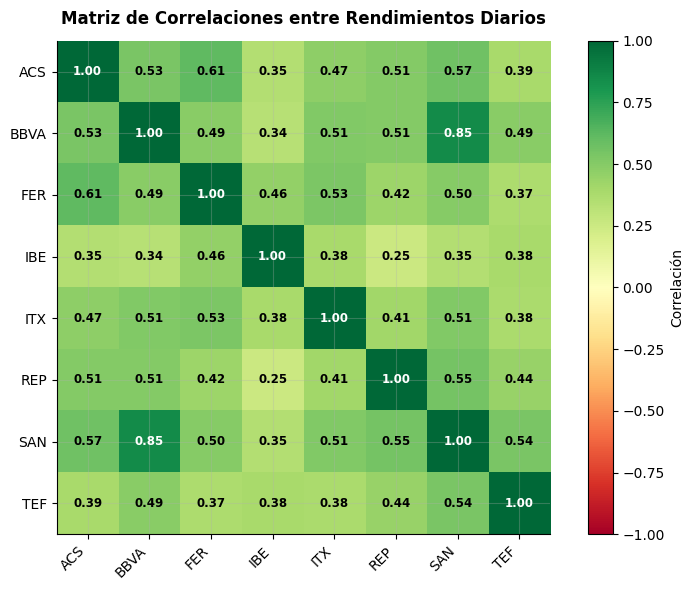

In [59]:
corr = returns.corr()
labels = [t.replace('.MC', '') for t in corr.columns]

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr.values, cmap='RdYlGn', vmin=-1, vmax=1)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center',
                fontsize=8.5, color='white' if abs(v) > 0.65 else 'black',
                fontweight='bold')
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.set_title('Matriz de Correlaciones entre Rendimientos Diarios',
             fontsize=12, fontweight='bold', pad=12)
plt.colorbar(im, ax=ax, label='Correlación')
plt.tight_layout()
plt.savefig('matriz_correlaciones_hito4.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Clase `PortfolioOptimizer`

Implementación de la clase de optimización. Utiliza `scipy.optimize.minimize`
con el método **SLSQP** (Sequential Least Squares Programming), que maneja
correctamente restricciones de igualdad y desigualdad simultáneamente.

### Problemas de optimización resueltos

**MVP** — Mínima Varianza Global:
$$\min_w \; w^T \Sigma w \quad \text{s.t.} \quad \mathbf{1}^T w = 1, \quad w_{min} \leq w_i \leq w_{max}$$

**MSR** — Máximo Ratio de Sharpe:
$$\max_w \; \frac{w^T \mu - r_f}{\sqrt{w^T \Sigma w}} \quad \text{s.t.} \quad \mathbf{1}^T w = 1, \quad w_{min} \leq w_i \leq w_{max}$$

**Frontera Eficiente** — N carteras con rendimiento objetivo $r^*$:
$$\min_w \; w^T \Sigma w \quad \text{s.t.} \quad w^T \mu = r^*, \quad \mathbf{1}^T w = 1, \quad w_{min} \leq w_i \leq w_{max}$$


In [60]:
@dataclass
class PortfolioResult:
    """
    Contenedor de resultados de una cartera optimizada.
    Agrupa pesos y métricas financieras clave.
    """
    weights:         pd.Series
    expected_return: float
    volatility:      float
    sharpe_ratio:    float
    label:           str = 'Cartera óptima'

    def summary(self):
        lines = [
            f'  Cartera     : {self.label}',
            f'  Rendimiento : {self.expected_return*100:.2f}%',
            f'  Volatilidad : {self.volatility*100:.2f}%',
            f'  Sharpe      : {self.sharpe_ratio:.4f}',
            f'  Pesos:',
        ] + [f'    {t:<14}: {w*100:.2f}%' for t, w in self.weights.items()]
        print('\n'.join(lines))


class PortfolioOptimizer:
    """
    Optimizador de carteras — Teoría Moderna de Carteras (Markowitz, 1952).

    Parameters
    ----------
    returns : pd.DataFrame       Rendimientos logarítmicos diarios (Hito 3)
    risk_free_rate : float       Tasa libre de riesgo anual (fracción)
    w_min : float                Peso mínimo por activo (def. 0.0)
    w_max : float                Peso máximo por activo (def. 1.0)
    """

    def __init__(self, returns, risk_free_rate=0.0, w_min=0.0, w_max=1.0):
        self.tickers        = list(returns.columns)
        self.n_assets       = len(self.tickers)
        self.risk_free_rate = risk_free_rate
        self.w_min          = w_min
        self.w_max          = w_max

        # Estimación de parámetros anualizados
        self.mu    = returns.mean().values * TRADING_DAYS_YEAR
        self.sigma = returns.cov().values  * TRADING_DAYS_YEAR

        logger.info('PortfolioOptimizer: %d activos | rf=%.1f%% | w=[%.0f%%,%.0f%%]',
                    self.n_assets, risk_free_rate*100, w_min*100, w_max*100)

    def _portfolio_metrics(self, w):
        """Calcula rendimiento, volatilidad y Sharpe de un vector de pesos."""
        ret = float(w @ self.mu)
        vol = float(np.sqrt(w @ self.sigma @ w))
        sr  = (ret - self.risk_free_rate) / vol if vol > 1e-10 else 0.0
        return ret, vol, sr

    def _solve(self, objective, extra_constraints=None):
        """
        Ejecuta SLSQP con múltiples puntos de inicio para robustez.
        Devuelve el mejor resultado encontrado.
        """
        # Restricciones base: suma de pesos = 1
        constraints = [{'type': 'eq', 'fun': lambda w: w.sum() - 1.0}]
        if extra_constraints:
            constraints.extend(extra_constraints)

        # Bounds: w_min ≤ w_i ≤ w_max para cada activo
        bounds = [(self.w_min, self.w_max)] * self.n_assets

        # Puntos de inicio: equi-ponderada + 3 aleatorios (semilla fija)
        rng = np.random.default_rng(seed=42)
        w0_list = [np.ones(self.n_assets) / self.n_assets]
        for _ in range(3):
            w0 = rng.dirichlet(np.ones(self.n_assets))
            w0 = np.clip(w0, self.w_min, self.w_max)
            w0_list.append(w0 / w0.sum())

        best = None
        for w0 in w0_list:
            res = minimize(objective, w0, method='SLSQP', bounds=bounds,
                           constraints=constraints,
                           options={'ftol': 1e-12, 'maxiter': 1000, 'disp': False})
            if res.success and (best is None or res.fun < best.fun):
                best = res

        if best is None:
            # Fallback: cartera equi-ponderada si la optimización no converge
            best = type('R', (), {'x': np.ones(self.n_assets)/self.n_assets})()

        w_opt = np.clip(best.x, 0.0, 1.0)
        w_opt /= w_opt.sum()  # garantizar suma = 1
        return w_opt

    def min_variance(self):
        """
        Cartera de Mínima Varianza Global (MVP).
        Minimiza w^T·Sigma·w sin restricción de rendimiento.
        """
        logger.info('Optimizando MVP...')
        # Función objetivo: varianza de la cartera
        w_opt = self._solve(objective=lambda w: float(w @ self.sigma @ w))
        ret, vol, sr = self._portfolio_metrics(w_opt)
        return PortfolioResult(
            weights=pd.Series(w_opt, index=self.tickers),
            expected_return=ret, volatility=vol, sharpe_ratio=sr,
            label='Mínima Varianza'
        )

    def max_sharpe(self):
        """
        Cartera de Máximo Ratio de Sharpe (MSR).
        Maximiza (w^T·mu - rf) / sqrt(w^T·Sigma·w).
        Equivale a minimizar el negativo del ratio de Sharpe.
        """
        logger.info('Optimizando MSR...')
        rf = self.risk_free_rate

        def neg_sharpe(w):
            # Negativo del Sharpe (scipy solo minimiza)
            ret = float(w @ self.mu)
            vol = float(np.sqrt(w @ self.sigma @ w))
            return -(ret - rf) / vol if vol > 1e-10 else 0.0

        w_opt = self._solve(objective=neg_sharpe)
        ret, vol, sr = self._portfolio_metrics(w_opt)
        return PortfolioResult(
            weights=pd.Series(w_opt, index=self.tickers),
            expected_return=ret, volatility=vol, sharpe_ratio=sr,
            label='Máximo Sharpe'
        )

    def efficient_frontier(self, n_points=100):
        """
        Calcula N puntos de la Frontera Eficiente.
        Para cada rendimiento objetivo r* resuelve:
            min w^T·Sigma·w  s.t. w^T·mu = r*
        Devuelve un DataFrame con volatilidad, rendimiento y pesos.
        """
        logger.info('Calculando Frontera Eficiente (%d puntos)...', n_points)
        mvp    = self.min_variance()
        r_min  = mvp.expected_return
        r_max  = self.mu.max() * 0.95
        targets = np.linspace(r_min, r_max, n_points)

        records = []
        for r_star in targets:
            constraint_ret = {'type': 'eq',
                              'fun': lambda w, rs=r_star: float(w @ self.mu) - rs}
            w_opt = self._solve(
                objective=lambda w: float(w @ self.sigma @ w),
                extra_constraints=[constraint_ret]
            )
            ret, vol, sr = self._portfolio_metrics(w_opt)
            row = {'volatility': vol, 'expected_return': ret, 'sharpe_ratio': sr}
            for t, w in zip(self.tickers, w_opt):
                row[f'w_{t}'] = w
            records.append(row)

        df = pd.DataFrame(records).sort_values('volatility').reset_index(drop=True)
        logger.info('Frontera Eficiente: %d puntos calculados.', len(df))
        return df

    def equal_weight(self):
        """Cartera equi-ponderada (1/N) como benchmark de referencia."""
        w = np.ones(self.n_assets) / self.n_assets
        ret, vol, sr = self._portfolio_metrics(w)
        return PortfolioResult(
            weights=pd.Series(w, index=self.tickers),
            expected_return=ret, volatility=vol, sharpe_ratio=sr,
            label='Equi-ponderada (1/N)'
        )


print('Clase PortfolioOptimizer definida correctamente.')


Clase PortfolioOptimizer definida correctamente.


## 6. Cartera de Mínima Varianza Global (MVP)

La MVP es el punto de menor riesgo posible de la frontera eficiente.
Minimiza la varianza sin imponer ningún objetivo de rendimiento.

In [61]:
opt = PortfolioOptimizer(
    returns        = returns,
    risk_free_rate = RISK_FREE_RATE,
    w_min          = W_MIN,
    w_max          = W_MAX,
)

mvp = opt.min_variance()
print('── Cartera de Mínima Varianza Global (MVP) ──────────────────')
mvp.summary()


2026-04-25 19:31:09  [INFO]  athena.hito4 — PortfolioOptimizer: 8 activos | rf=3.5% | w=[0%,40%]
2026-04-25 19:31:09  [INFO]  athena.hito4 — Optimizando MVP...


── Cartera de Mínima Varianza Global (MVP) ──────────────────
  Cartera     : Mínima Varianza
  Rendimiento : 10.79%
  Volatilidad : 18.42%
  Sharpe      : 0.3957
  Pesos:
    ACS.MC        : 0.00%
    BBVA.MC       : 0.00%
    FER.MC        : 18.96%
    IBE.MC        : 40.00%
    ITX.MC        : 13.92%
    REP.MC        : 7.34%
    SAN.MC        : 0.00%
    TEF.MC        : 19.78%


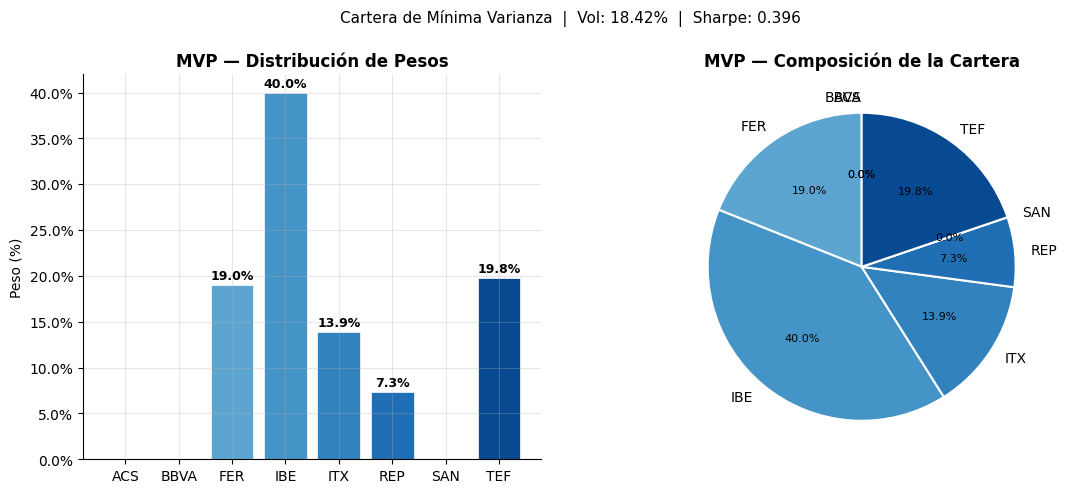

In [62]:
# Visualizar distribución de pesos — MVP
labels_plot = [t.replace('.MC', '') for t in mvp.weights.index]
weights_pct = mvp.weights.values * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico de barras
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(labels_plot)))
bars = ax1.bar(labels_plot, weights_pct, color=colors, edgecolor='white', linewidth=0.5)
for bar, val in zip(bars, weights_pct):
    if val > 0.5:
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax1.set_title('MVP — Distribución de Pesos', fontweight='bold')
ax1.set_ylabel('Peso (%)')
ax1.yaxis.set_major_formatter(mtick.PercentFormatter())

# Gráfico de tarta
wedges, texts, autotexts = ax2.pie(
    weights_pct, labels=labels_plot, autopct='%1.1f%%',
    colors=colors, startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
for at in autotexts:
    at.set_fontsize(8)
ax2.set_title('MVP — Composición de la Cartera', fontweight='bold')

plt.suptitle(f'Cartera de Mínima Varianza  |  Vol: {mvp.volatility*100:.2f}%  |  Sharpe: {mvp.sharpe_ratio:.3f}',
             fontsize=11, y=1.01)
plt.savefig('mvp_pesos.png', dpi=150, bbox_inches='tight')
plt.show()


## 7. Cartera de Máximo Ratio de Sharpe (MSR)

La MSR es la cartera tangente — el punto de la frontera eficiente donde
la línea que parte del activo libre de riesgo es tangente a la frontera.
Maximiza el rendimiento por unidad de riesgo.

In [63]:
msr = opt.max_sharpe()
print('── Cartera de Máximo Ratio de Sharpe (MSR) ──────────────────')
msr.summary()


2026-04-25 19:31:09  [INFO]  athena.hito4 — Optimizando MSR...


── Cartera de Máximo Ratio de Sharpe (MSR) ──────────────────
  Cartera     : Máximo Sharpe
  Rendimiento : 15.62%
  Volatilidad : 19.54%
  Sharpe      : 0.6202
  Pesos:
    ACS.MC        : 0.00%
    BBVA.MC       : 5.63%
    FER.MC        : 29.93%
    IBE.MC        : 40.00%
    ITX.MC        : 24.44%
    REP.MC        : 0.00%
    SAN.MC        : 0.00%
    TEF.MC        : 0.00%


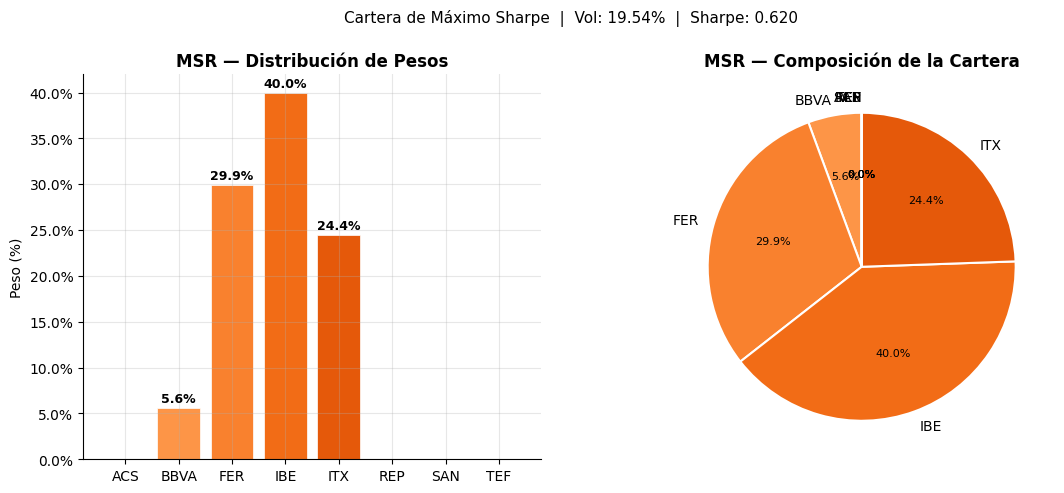

In [64]:
# Visualizar distribución de pesos — MSR
labels_plot = [t.replace('.MC', '') for t in msr.weights.index]
weights_pct = msr.weights.values * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
colors = plt.cm.Oranges(np.linspace(0.4, 0.9, len(labels_plot)))

bars = ax1.bar(labels_plot, weights_pct, color=colors, edgecolor='white', linewidth=0.5)
for bar, val in zip(bars, weights_pct):
    if val > 0.5:
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax1.set_title('MSR — Distribución de Pesos', fontweight='bold')
ax1.set_ylabel('Peso (%)')
ax1.yaxis.set_major_formatter(mtick.PercentFormatter())

wedges, texts, autotexts = ax2.pie(
    weights_pct, labels=labels_plot, autopct='%1.1f%%',
    colors=colors, startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
for at in autotexts:
    at.set_fontsize(8)
ax2.set_title('MSR — Composición de la Cartera', fontweight='bold')

plt.suptitle(f'Cartera de Máximo Sharpe  |  Vol: {msr.volatility*100:.2f}%  |  Sharpe: {msr.sharpe_ratio:.3f}',
             fontsize=11, y=1.01)
plt.savefig('msr_pesos.png', dpi=150, bbox_inches='tight')
plt.show()


## 8. Frontera Eficiente completa

Calculamos 100 carteras óptimas para trazar la curva completa de la
Frontera Eficiente en el espacio riesgo-rendimiento.

In [65]:
frontier = opt.efficient_frontier(n_points=100)

print(f'Puntos calculados: {len(frontier)}')
print(f'Rango volatilidad : {frontier["volatility"].min()*100:.2f}% — {frontier["volatility"].max()*100:.2f}%')
print(f'Rango rendimiento : {frontier["expected_return"].min()*100:.2f}% — {frontier["expected_return"].max()*100:.2f}%')
print()
print('Primeras 5 filas:')
print(frontier[['volatility','expected_return','sharpe_ratio']]
      .head(5)
      .assign(volatility=lambda x: x.volatility*100,
              expected_return=lambda x: x.expected_return*100)
      .round(3)
      .to_string())


2026-04-25 19:31:10  [INFO]  athena.hito4 — Calculando Frontera Eficiente (100 puntos)...
2026-04-25 19:31:10  [INFO]  athena.hito4 — Optimizando MVP...
2026-04-25 19:31:15  [INFO]  athena.hito4 — Frontera Eficiente: 100 puntos calculados.


Puntos calculados: 100
Rango volatilidad : 18.42% — 22.18%
Rango rendimiento : 10.79% — 16.18%

Primeras 5 filas:
   volatility  expected_return  sharpe_ratio
0     18.4200          10.7880        0.3960
1     18.4200          10.8430        0.3990
2     18.4210          10.8970        0.4020
3     18.4210          10.9520        0.4050
4     18.4220          11.0060        0.4070


## 9. Visualización — Gráfico de Frontera Eficiente

Este gráfico es el elemento central del dashboard del Proyecto Athena.
Muestra el espacio riesgo-rendimiento con carteras simuladas (nube de puntos),
la curva de la Frontera Eficiente y los puntos MVP y MSR destacados.

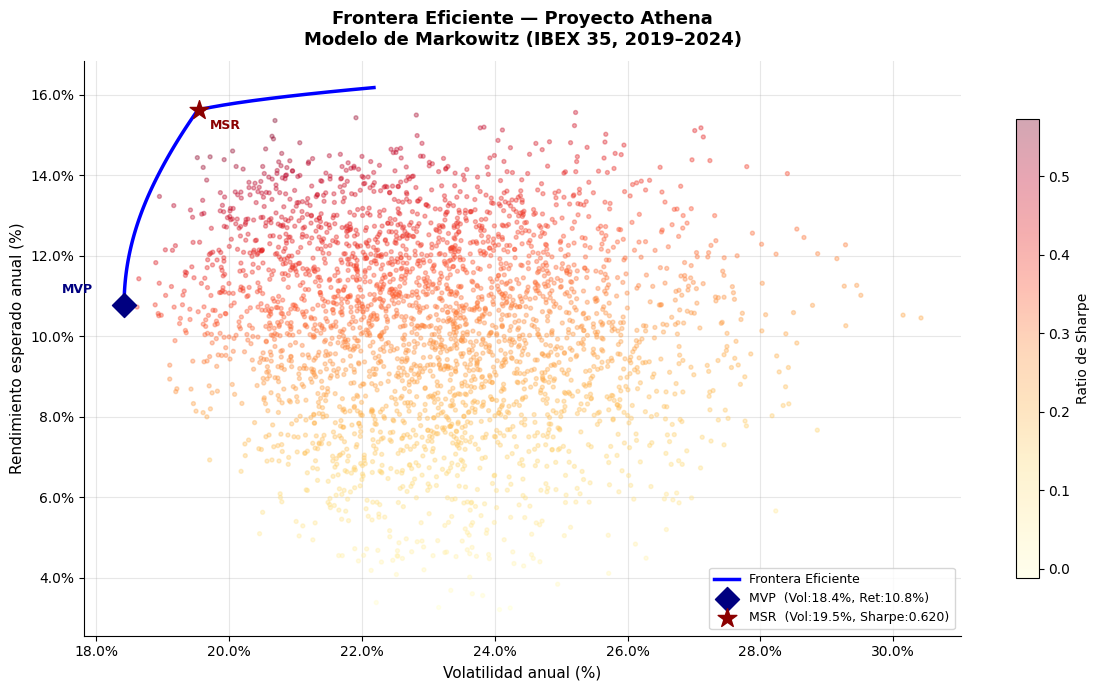

Gráfico guardado: frontera_eficiente.png


In [66]:
# Generar nube de carteras aleatorias para contexto visual
np.random.seed(0)
N_SIM = 3000
sim_vols, sim_rets, sim_sr = [], [], []

for _ in range(N_SIM):
    w = np.random.dirichlet(np.ones(opt.n_assets))
    w = np.clip(w, W_MIN, W_MAX)
    w /= w.sum()
    ret = float(w @ opt.mu)
    vol = float(np.sqrt(w @ opt.sigma @ w))
    sr  = (ret - RISK_FREE_RATE) / vol if vol > 1e-10 else 0
    sim_vols.append(vol * 100)
    sim_rets.append(ret * 100)
    sim_sr.append(sr)

# ── Gráfico completo de Frontera Eficiente ──
fig, ax = plt.subplots(figsize=(12, 7))

# Nube de carteras simuladas (coloreadas por Sharpe)
sc = ax.scatter(sim_vols, sim_rets, c=sim_sr, cmap='YlOrRd',
                alpha=0.35, s=8, zorder=2)
plt.colorbar(sc, ax=ax, label='Ratio de Sharpe', shrink=0.8)

# Curva de la Frontera Eficiente
fe_vols = frontier['volatility'].values * 100
fe_rets = frontier['expected_return'].values * 100
ax.plot(fe_vols, fe_rets, 'b-', linewidth=2.5,
        label='Frontera Eficiente', zorder=4)

# Punto MVP
ax.scatter(mvp.volatility*100, mvp.expected_return*100,
           color='navy', s=150, zorder=6, marker='D',
           label=f'MVP  (Vol:{mvp.volatility*100:.1f}%, Ret:{mvp.expected_return*100:.1f}%)')
ax.annotate('MVP', (mvp.volatility*100, mvp.expected_return*100),
            textcoords='offset points', xytext=(-45, 8),
            fontsize=9, color='navy', fontweight='bold')

# Punto MSR
ax.scatter(msr.volatility*100, msr.expected_return*100,
           color='darkred', s=200, zorder=6, marker='*',
           label=f'MSR  (Vol:{msr.volatility*100:.1f}%, Sharpe:{msr.sharpe_ratio:.3f})')
ax.annotate('MSR', (msr.volatility*100, msr.expected_return*100),
            textcoords='offset points', xytext=(8, -14),
            fontsize=9, color='darkred', fontweight='bold')

ax.set_xlabel('Volatilidad anual (%)', fontsize=11)
ax.set_ylabel('Rendimiento esperado anual (%)', fontsize=11)
ax.set_title('Frontera Eficiente — Proyecto Athena\n'
             'Modelo de Markowitz (IBEX 35, 2019–2024)',
             fontsize=13, fontweight='bold', pad=12)
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter('%.1f%%'))
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter('%.1f%%'))
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig('frontera_eficiente.png', dpi=150, bbox_inches='tight')
plt.show()
print('Gráfico guardado: frontera_eficiente.png')


## 10. Comparativa de carteras

Comparamos las dos carteras optimizadas con la cartera equi-ponderada
(1/N) como benchmark de referencia.

In [67]:
eq = opt.equal_weight()

print('── Comparativa de carteras ────────────────────────────────────')
print(f'{'Cartera':<26} {'Rendimiento':>12} {'Volatilidad':>12} {'Sharpe':>10}')
print('-' * 62)
for pf in [mvp, msr, eq]:
    print(f'{pf.label:<26} {pf.expected_return*100:>11.2f}% '
          f'{pf.volatility*100:>11.2f}% {pf.sharpe_ratio:>10.4f}')
print('-' * 62)
print()
print(f'Mejora Sharpe MSR vs equi-ponderada: '
      f'{((msr.sharpe_ratio/eq.sharpe_ratio)-1)*100:.1f}%')
print(f'Reducción volatilidad MVP vs equi-ponderada: '
      f'{((mvp.volatility/eq.volatility)-1)*100:.1f}%')


── Comparativa de carteras ────────────────────────────────────
Cartera                     Rendimiento  Volatilidad     Sharpe
--------------------------------------------------------------
Mínima Varianza                  10.79%       18.42%     0.3957
Máximo Sharpe                    15.62%       19.54%     0.6202
Equi-ponderada (1/N)             10.27%       22.24%     0.3042
--------------------------------------------------------------

Mejora Sharpe MSR vs equi-ponderada: 103.9%
Reducción volatilidad MVP vs equi-ponderada: -17.2%


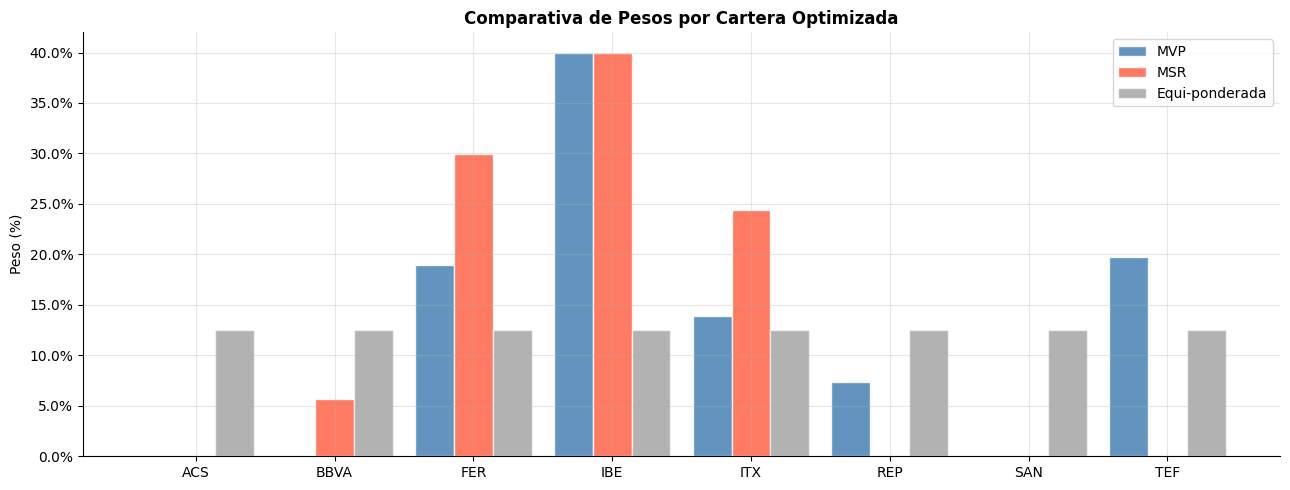

In [68]:
# Gráfico comparativo de pesos por cartera
labels_plot = [t.replace('.MC', '') for t in opt.tickers]
x = np.arange(len(labels_plot))
width = 0.28

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - width, mvp.weights*100, width, label='MVP', color='steelblue',
       edgecolor='white', alpha=0.85)
ax.bar(x,         msr.weights*100, width, label='MSR', color='tomato',
       edgecolor='white', alpha=0.85)
ax.bar(x + width, eq.weights*100,  width, label='Equi-ponderada',
       color='gray', edgecolor='white', alpha=0.60)

ax.set_xticks(x)
ax.set_xticklabels(labels_plot, fontsize=10)
ax.set_ylabel('Peso (%)')
ax.set_title('Comparativa de Pesos por Cartera Optimizada',
             fontsize=12, fontweight='bold')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend()
plt.tight_layout()
plt.savefig('comparativa_pesos.png', dpi=150, bbox_inches='tight')
plt.show()


## 11. Resumen y outputs para el Hito 5

El Hito 4 produce los siguientes outputs que alimentan el **Módulo de
Simulación Monte Carlo (Hito 5)**:

| Variable | Tipo | Descripción |
|----------|------|-------------|
| `mvp` | `PortfolioResult` | Pesos y métricas de la cartera de mínima varianza |
| `msr` | `PortfolioResult` | Pesos y métricas de la cartera de máximo Sharpe |
| `frontier` | `pd.DataFrame` | 100 puntos de la Frontera Eficiente |
| `opt.mu` | `np.ndarray` | Vector de rendimientos esperados anualizados |
| `opt.sigma` | `np.ndarray` | Matriz de covarianzas anualizadas |

### Integración con el Hito 5

```python
# Hito 5 — Simulación Monte Carlo
# La cartera óptima (MSR) es el input de las simulaciones:
weights_opt = msr.weights.values

# N_SIM escenarios de rendimientos futuros durante HORIZON días:
# -> simulaciones[i, t] = rendimiento acumulado del escenario i en el día t
# -> VaR y CVaR calculados sobre la distribución de rendimientos finales
```

In [69]:
print('=' * 65)
print('  RESUMEN DEL HITO 4 — Optimización de Carteras')
print('=' * 65)
print(f'  Activos             : {opt.n_assets}')
print(f'  Tasa libre de riesgo: {RISK_FREE_RATE*100:.1f}%')
print(f'  Restricciones pesos : [{W_MIN*100:.0f}%, {W_MAX*100:.0f}%]')
print()
print(f'  MVP — Vol: {mvp.volatility*100:.2f}% | Ret: {mvp.expected_return*100:.2f}% | Sharpe: {mvp.sharpe_ratio:.4f}')
print(f'  MSR — Vol: {msr.volatility*100:.2f}% | Ret: {msr.expected_return*100:.2f}% | Sharpe: {msr.sharpe_ratio:.4f}')
print(f'  Frontera Eficiente : {len(frontier)} puntos')
print()
print('  Archivos generados:')
import os
for f in ['frontera_eficiente.png', 'mvp_pesos.png', 'msr_pesos.png',
          'comparativa_pesos.png', 'matriz_correlaciones_hito4.png']:
    exists = '✓' if os.path.exists(f) else '✗'
    print(f'    {exists} {f}')
print('=' * 65)


  RESUMEN DEL HITO 4 — Optimización de Carteras
  Activos             : 8
  Tasa libre de riesgo: 3.5%
  Restricciones pesos : [0%, 40%]

  MVP — Vol: 18.42% | Ret: 10.79% | Sharpe: 0.3957
  MSR — Vol: 19.54% | Ret: 15.62% | Sharpe: 0.6202
  Frontera Eficiente : 100 puntos

  Archivos generados:
    ✓ frontera_eficiente.png
    ✓ mvp_pesos.png
    ✓ msr_pesos.png
    ✓ comparativa_pesos.png
    ✓ matriz_correlaciones_hito4.png
